### Machine Learning – Assignment 2

**Topic:** Implementation and Comparison of Classification Models

**Dataset:** Wisconsin Diagnostic Breast Cancer Dataset

**Student Name:** Shivam Bajpai

**Bits ID**: 2026AJ05745

In [1]:

!pip install -q numpy pandas scikit-learn matplotlib seaborn joblib streamlit


In [2]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.datasets import load_breast_cancer

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")


All libraries imported successfully!


## Q1. Dataset Selection and Description

For this assignment, I have selected the Wisconsin Diagnostic Breast Cancer dataset. It is a binary classification dataset containing numerical measurements of breast mass samples.

The dataset is used to classify samples into two categories: malignant and benign.

The dataset contains 569 instances and 30 input features. It is suitable for implementing and comparing different machine learning classification algorithms.

In [3]:

# Load the Wisconsin Breast Cancer dataset

dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

# Combine features and target
df = X.copy()
df["target"] = y

print("Dataset loaded successfully!")

print("\nDataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nTarget classes:")
print(dataset.target_names)

print("\nClass distribution:")
print(y.value_counts())


Dataset loaded successfully!

Dataset shape: (569, 31)

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Target classes:
['malignant' 'benign']

Class distribution:
target
1    357
0    212
Name: count, dtype: int64


In [4]:

# Check dataset information

print("Dataset Information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nNumber of features:", X.shape[1])
print("Number of instances:", X.shape[0])

print("\nStatistical description:")
display(X.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


## Step 5: Exploratory Data Analysis

In this step, I perform exploratory data analysis to understand the distribution of the target classes and the relationship between the input features.

I also visualize the class distribution and examine the correlation between numerical features.

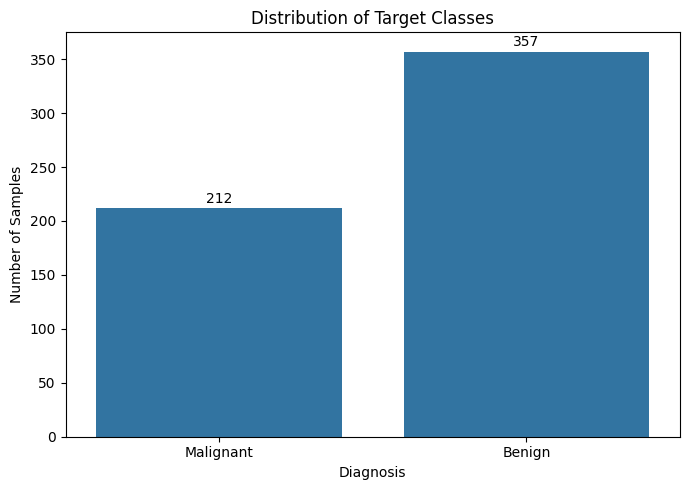

In [5]:

# Count the target classes

class_counts = y.value_counts().sort_index()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=["Malignant", "Benign"],
    y=class_counts.values
)

plt.title("Distribution of Target Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")

for i, value in enumerate(class_counts.values):
    plt.text(i, value + 5, str(value), ha="center")

plt.tight_layout()
plt.show()


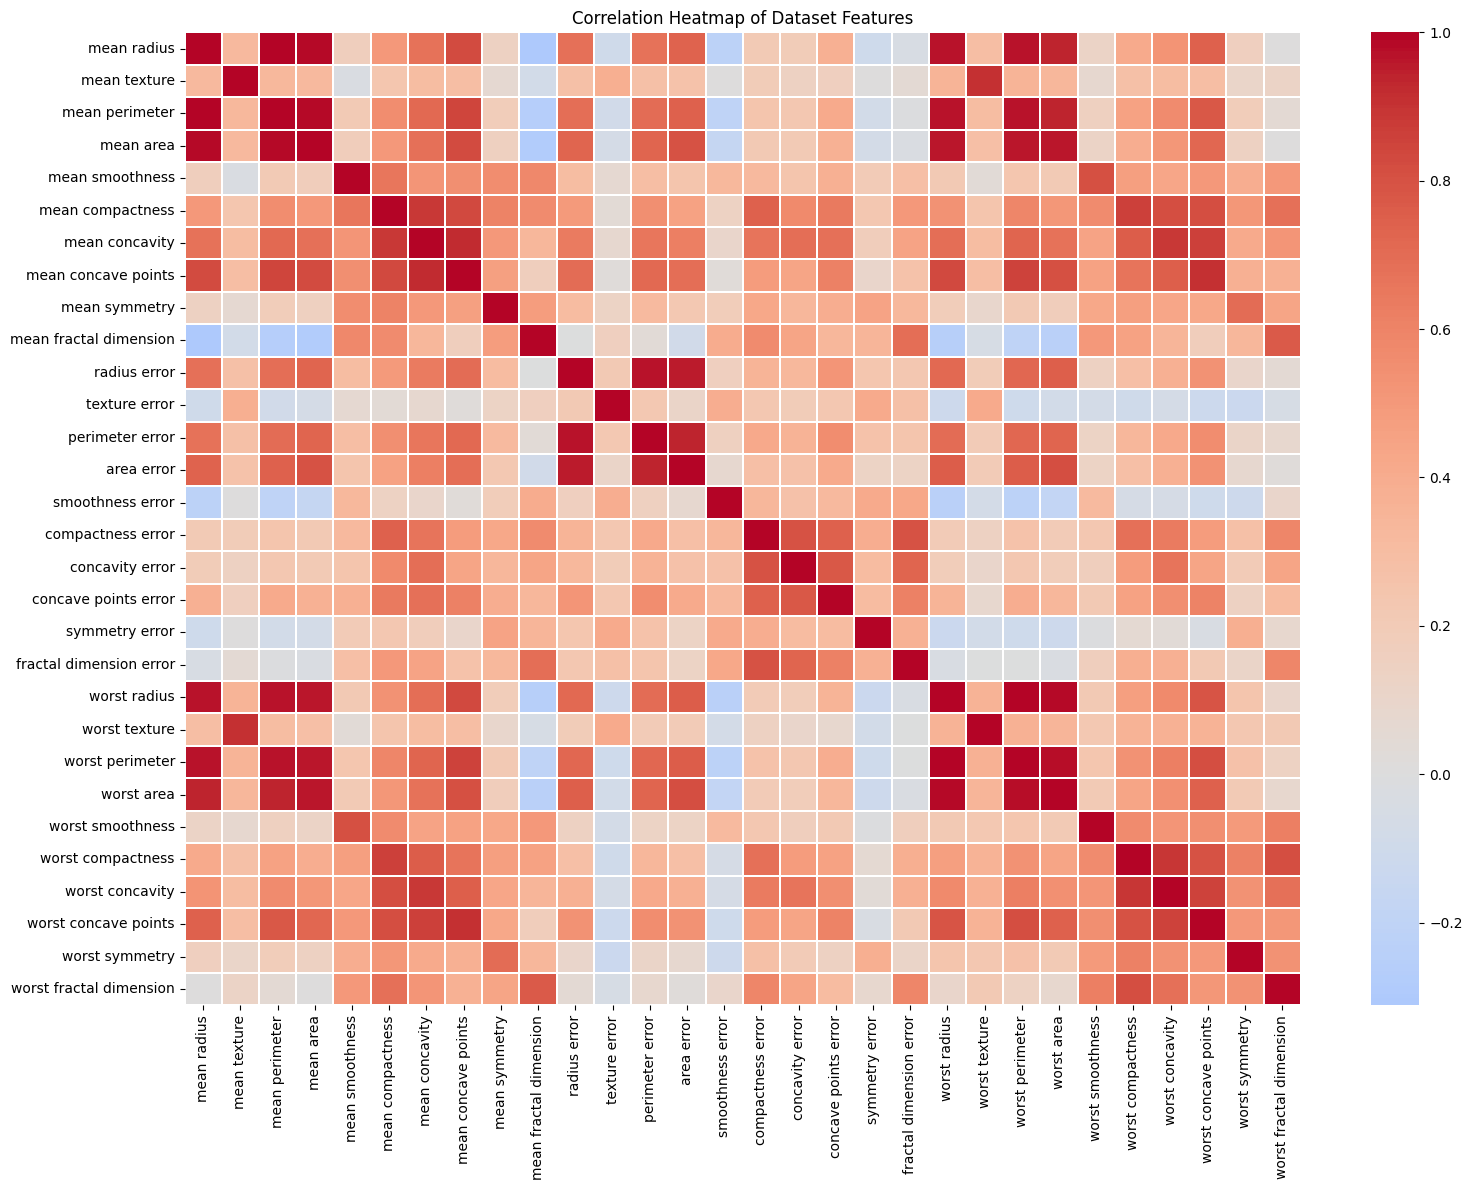

In [6]:

# Correlation between input features

correlation = X.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Dataset Features")
plt.tight_layout()
plt.show()


In [7]:

# Calculate class percentages

class_percentage = y.value_counts(normalize=True) * 100

print("Class distribution in percentage:")
print("Malignant:", round(class_percentage[0], 2), "%")
print("Benign:", round(class_percentage[1], 2), "%")


Class distribution in percentage:
Malignant: 37.26 %
Benign: 62.74 %


## Step 6: Train-Test Split

The dataset is divided into training and testing sets using an 80:20 ratio. Stratified sampling is used to maintain the proportion of malignant and benign samples in both sets.

A random state of 42 is used to make the experiment reproducible.

In [8]:

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and testing split completed!")

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training and testing split completed!

Training data shape: (455, 30)
Testing data shape: (114, 30)

Training target distribution:
target
1    285
0    170
Name: count, dtype: int64

Testing target distribution:
target
1    72
0    42
Name: count, dtype: int64


In [9]:

# Create folders to save trained models and results

os.makedirs("model", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Project folders created successfully!")


Project folders created successfully!


## Step 7: Implementation of Classification Models

In this step, I implement five classification algorithms using Scikit-learn. All five models are trained using the same training dataset.

StandardScaler is used for Logistic Regression, KNN, Gaussian Naive Bayes and SVM because these algorithms can be affected by differences in feature scales. The Decision Tree model is used without feature scaling.

In [10]:

# Define all five classification models

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ]),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ])
}

print("All five classification models defined successfully!")

for model_name in models:
    print("-", model_name)


All five classification models defined successfully!
- Logistic Regression
- Decision Tree
- KNN
- Naive Bayes
- Support Vector Machine


### Model Training

Each classification model is trained using the training dataset. After training, the fitted models are saved so that they can be reused later in the Streamlit application without training them again.

In [11]:

# Train all five models

trained_models = {}

for name, model in models.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(name, "trained successfully!\n")

print("All five models have been trained.")


Training: Logistic Regression
Logistic Regression trained successfully!

Training: Decision Tree
Decision Tree trained successfully!

Training: KNN
KNN trained successfully!

Training: Naive Bayes
Naive Bayes trained successfully!

Training: Support Vector Machine
Support Vector Machine trained successfully!

All five models have been trained.


### Model Evaluation

After training the models, I evaluate their performance using the testing dataset. Six evaluation metrics are calculated for each classifier to compare their classification performance.

The same testing dataset is used for all five models to ensure a fair comparison.

In [12]:

# Evaluate all five trained models

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

results = []

for name, model in trained_models.items():

    # Predict test data
    y_pred = model.predict(X_test)

    # Probability of positive class (class 1 = benign)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "ML Model Name": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

# Create comparison table
results_df = pd.DataFrame(results)

print("CLASSIFICATION MODEL EVALUATION RESULTS")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "MCC": "{:.4f}"
    })
)


CLASSIFICATION MODEL EVALUATION RESULTS


,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
1,Decision Tree,0.9211,0.9163,0.9565,0.9167,0.9362,0.8341
2,KNN,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
3,Naive Bayes,0.9298,0.9868,0.9444,0.9444,0.9444,0.8492
4,Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


In [14]:

# Save all trained models

import joblib

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "support_vector_machine.joblib"
}

for name, model in trained_models.items():

    file_name = model_files[name]

    joblib.dump(model, f"model/{file_name}")

    print(name, "saved successfully!")

print("\nAll five models saved in the model folder.")


Logistic Regression saved successfully!
Decision Tree saved successfully!
KNN saved successfully!
Naive Bayes saved successfully!
Support Vector Machine saved successfully!

All five models saved in the model folder.


In [15]:

# Save model comparison results

results_df.to_csv("results/metrics.csv", index=False)

# Save test data with target column
test_data = X_test.copy()
test_data["target"] = y_test

test_data.to_csv("test_data.csv", index=False)

print("Evaluation results saved successfully!")
print("Test dataset saved successfully!")

print("\nTest dataset shape:", test_data.shape)


Evaluation results saved successfully!
Test dataset saved successfully!

Test dataset shape: (114, 31)


In [16]:

print("Saved model files:")

for file in os.listdir("model"):
    print(file)

print("\nSaved result files:")
print(os.listdir("results"))

print("\nTest CSV exists:", os.path.exists("test_data.csv"))


Saved model files:
knn.joblib
decision_tree.joblib
naive_bayes.joblib
support_vector_machine.joblib
logistic_regression.joblib

Saved result files:
['metrics.csv']

Test CSV exists: True


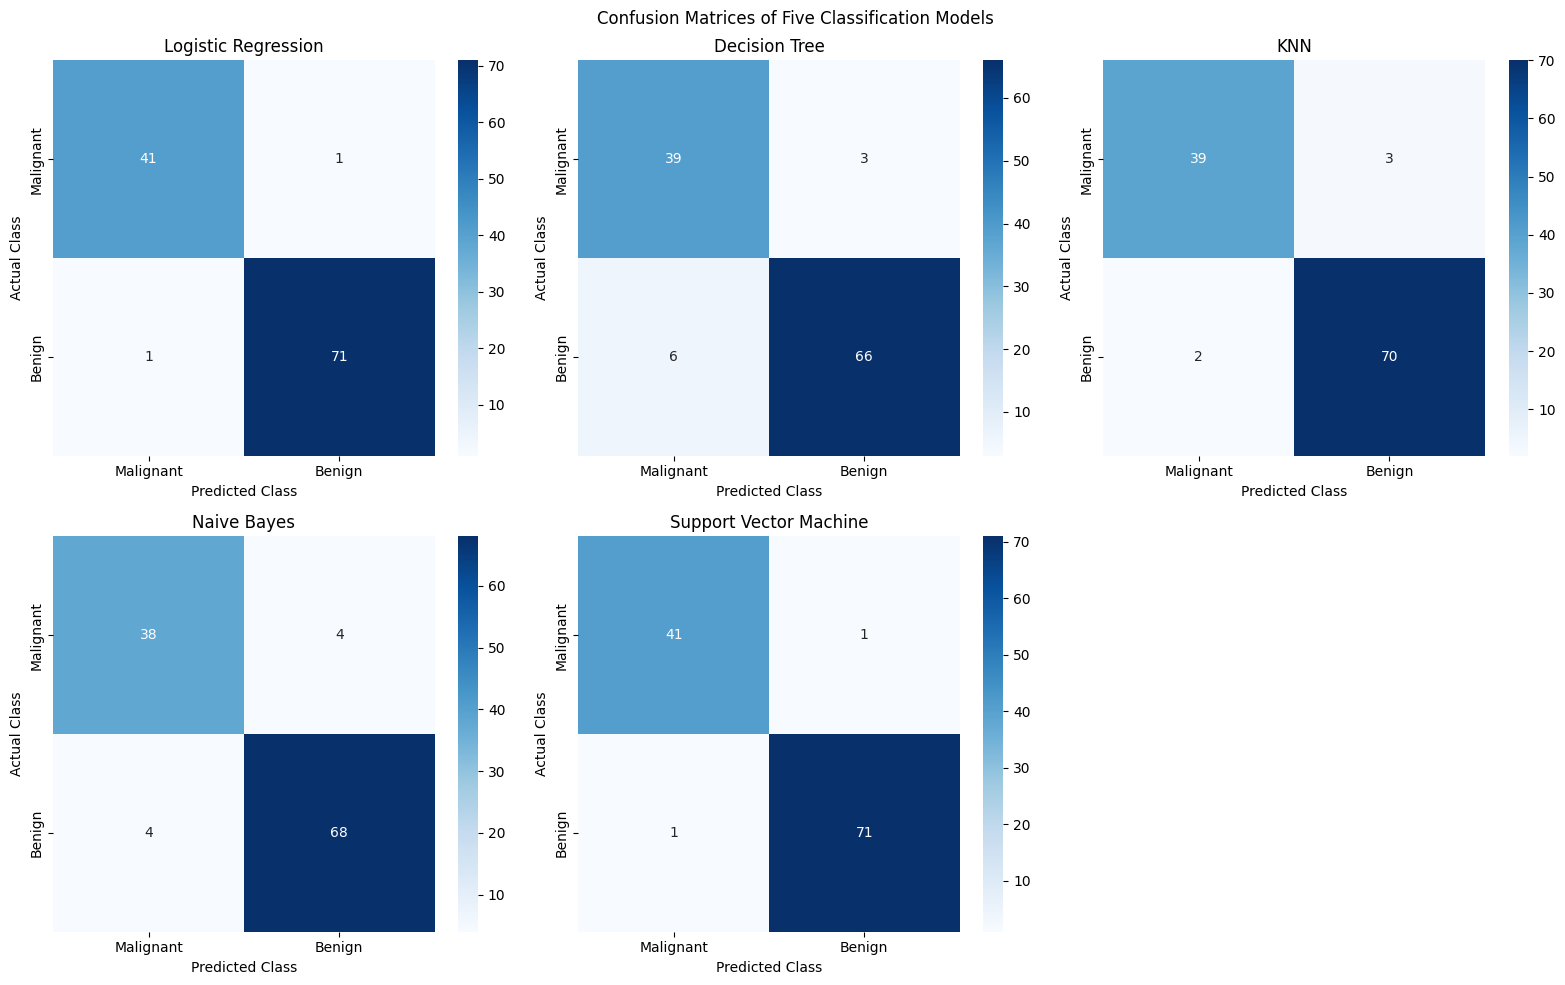

In [17]:

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(trained_models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Malignant", "Benign"],
        yticklabels=["Malignant", "Benign"],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Class")
    axes[i].set_ylabel("Actual Class")

# Remove the unused sixth panel
fig.delaxes(axes[5])

plt.suptitle("Confusion Matrices of Five Classification Models")
plt.tight_layout()
plt.show()


In [18]:

from sklearn.metrics import classification_report

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print("\n" + "=" * 55)
    print("MODEL:", name)
    print("=" * 55)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Malignant", "Benign"],
            zero_division=0
        )
    )



MODEL: Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


MODEL: Decision Tree
              precision    recall  f1-score   support

   Malignant       0.87      0.93      0.90        42
      Benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114


MODEL: KNN
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg

In [19]:

# Save the final comparison table

results_df.to_csv("results/metrics.csv", index=False)

print("Comparison table saved successfully!")

display(results_df.round(4))


Comparison table saved successfully!


,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
1,Decision Tree,0.9211,0.9163,0.9565,0.9167,0.9362,0.8341
2,KNN,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
3,Naive Bayes,0.9298,0.9868,0.9444,0.9444,0.9444,0.8492
4,Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


In [20]:

import os

print("MODEL DIRECTORY")

for filename in sorted(os.listdir("model")):
    print(filename)

print("\nRESULTS DIRECTORY")

for filename in sorted(os.listdir("results")):
    print(filename)

print("\nTEST DATA EXISTS:", os.path.exists("test_data.csv"))


MODEL DIRECTORY
decision_tree.joblib
knn.joblib
logistic_regression.joblib
naive_bayes.joblib
support_vector_machine.joblib

RESULTS DIRECTORY
metrics.csv

TEST DATA EXISTS: True


In [21]:

%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Page configuration
st.set_page_config(
    page_title="Breast Cancer ML Model Evaluation",
    page_icon="📊",
    layout="wide"
)

# Application heading
st.title("Machine Learning Classification Dashboard")

st.markdown("""
This application compares five machine learning classification
models using the Wisconsin Diagnostic Breast Cancer dataset.

Upload a labelled test CSV, select a model, and explore its
performance through evaluation metrics and visualizations.
""")

st.divider()

# Saved model locations
MODEL_FILES = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "K-Nearest Neighbors": "model/knn.joblib",
    "Gaussian Naive Bayes": "model/naive_bayes.joblib",
    "Support Vector Machine": "model/support_vector_machine.joblib"
}

# Expected feature columns
@st.cache_data
def load_feature_names():
    reference = pd.read_csv("test_data.csv")
    return [column for column in reference.columns if column != "target"]

feature_names = load_feature_names()

# Sidebar
st.sidebar.header("Evaluation Settings")

uploaded_file = st.sidebar.file_uploader(
    "Upload test dataset",
    type=["csv"]
)

selected_model = st.sidebar.selectbox(
    "Select classification model",
    list(MODEL_FILES.keys())
)

st.sidebar.caption(
    "The uploaded CSV must contain 30 input features "
    "and a target column."
)

# Evaluation function
def evaluate_model(model_name, X, y):

    model_path = MODEL_FILES[model_name]

    if not os.path.exists(model_path):
        raise FileNotFoundError(
            f"Model file not found: {model_path}"
        )

    model = joblib.load(model_path)

    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]

    scores = {
        "Accuracy": accuracy_score(y, predictions),
        "AUC": roc_auc_score(y, probabilities),
        "Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y, predictions, zero_division=0
        ),
        "MCC": matthews_corrcoef(y, predictions)
    }

    return model, predictions, scores


if uploaded_file is None:

    st.info("Upload your test_data.csv file using the sidebar.")

    st.subheader("Available Classification Models")

    col1, col2, col3 = st.columns(3)

    col1.metric("Total Models", "5")
    col2.metric("Input Features", "30")
    col3.metric("Dataset Type", "Binary")

    st.markdown("### Models included")

    for name in MODEL_FILES:
        st.write("•", name)

else:

    try:
        data = pd.read_csv(uploaded_file)

        st.subheader("Uploaded Dataset")

        st.write("Dataset shape:", data.shape)

        st.dataframe(data.head(), use_container_width=True)

        # Validate required columns
        if (
            len(data.columns) != len(feature_names) + 1
            or set(data.columns) != set(feature_names + ["target"])
        ):
            st.error(
                "Incorrect CSV structure. Please upload a file "
                "containing all 30 expected features and target."
            )

        elif data.isnull().any().any():
            st.error(
                "The uploaded dataset contains missing values."
            )

        elif not set(data["target"].unique()).issubset({0, 1}):
            st.error(
                "Target values must be 0 or 1."
            )

        elif data["target"].nunique() != 2:
            st.error(
                "The test dataset must contain both target classes "
                "to calculate AUC."
            )

        else:
            X = data[feature_names]
            y = data["target"].astype(int)

            # Evaluate selected model
            model, predictions, scores = evaluate_model(
                selected_model, X, y
            )

            st.divider()

            st.subheader(
                f"Performance: {selected_model}"
            )

            # Display metrics
            metric_names = [
                "Accuracy", "AUC", "Precision",
                "Recall", "F1 Score", "MCC"
            ]

            columns = st.columns(3)

            for index, metric in enumerate(metric_names):
                columns[index % 3].metric(
                    metric,
                    f"{scores[metric]:.4f}"
                )

            # Confusion matrix
            st.divider()
            st.subheader("Confusion Matrix")

            cm = confusion_matrix(
                y,
                predictions,
                labels=[0, 1]
            )

            fig, ax = plt.subplots(figsize=(7, 5))

            sns.heatmap(
                cm,
                annot=True,
                fmt="d",
                cmap="Blues",
                xticklabels=["Malignant", "Benign"],
                yticklabels=["Malignant", "Benign"],
                ax=ax
            )

            ax.set_xlabel("Predicted Class")
            ax.set_ylabel("Actual Class")
            ax.set_title(selected_model)

            st.pyplot(fig)
            plt.close(fig)

            # Classification report
            st.divider()
            st.subheader("Classification Report")

            report = classification_report(
                y,
                predictions,
                labels=[0, 1],
                target_names=["Malignant", "Benign"],
                output_dict=True,
                zero_division=0
            )

            report_df = pd.DataFrame(report).transpose()

            st.dataframe(
                report_df.round(4),
                use_container_width=True
            )

            # Compare all models
            st.divider()
            st.subheader("Comparison of All Five Models")

            comparison = []

            for name in MODEL_FILES:

                _, _, model_scores = evaluate_model(
                    name, X, y
                )

                comparison.append({
                    "Model": name,
                    **model_scores
                })

            comparison_df = pd.DataFrame(comparison)

            st.dataframe(
                comparison_df.round(4),
                use_container_width=True
            )

            # Download comparison results
            csv_data = comparison_df.to_csv(index=False)

            st.download_button(
                label="Download Model Comparison CSV",
                data=csv_data,
                file_name="model_comparison.csv",
                mime="text/csv"
            )

    except Exception as error:
        st.error(f"Unable to evaluate the uploaded data: {error}")

st.divider()

st.caption(
    "M.Tech AIML | Machine Learning Assignment 2 | BITS Pilani"
)


Writing app.py


In [22]:

%%writefile requirements.txt

streamlit
numpy
pandas
scikit-learn
matplotlib
seaborn
joblib


Writing requirements.txt


In [23]:

import os

print("Project files:")

for item in sorted(os.listdir(".")):
    print(item)

print("\nApplication exists:", os.path.exists("app.py"))
print("Requirements exists:", os.path.exists("requirements.txt"))


Project files:
.config
app.py
model
requirements.txt
results
sample_data
test_data.csv

Application exists: True
Requirements exists: True


In [24]:

%%writefile README.md

# BITS Pilani M.Tech AIML - Machine Learning Assignment 2

## 1. Problem Statement

The objective of this assignment is to implement and compare five machine learning classification algorithms using a common dataset.

The project also includes an interactive Streamlit application that allows users to upload test data, select a classification model and view its evaluation metrics.

## 2. Dataset Description

**Dataset:** Wisconsin Diagnostic Breast Cancer Dataset

**Source:** UCI Machine Learning Repository

**Dataset URL:** https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

- Total instances: 569
- Input features: 30
- Target classes: 2
- Classification type: Binary
- Missing values: 0

Target labels:
- 0: Malignant
- 1: Benign

The dataset was divided into 80% training data and 20% testing data using stratified sampling.

## 3. GitHub Repository Link

Add the GitHub repository URL after creating the repository.

## 4. Models Used and Evaluation Metrics

Five classification algorithms were implemented:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine

### Model Comparison

| Model | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.9825 | 0.9954 | 0.9861 | 0.9861 | 0.9861 | 0.9623 |
| Decision Tree | 0.9211 | 0.9163 | 0.9565 | 0.9167 | 0.9362 | 0.8341 |
| KNN | 0.9561 | 0.9788 | 0.9589 | 0.9722 | 0.9655 | 0.9054 |
| Naive Bayes | 0.9298 | 0.9868 | 0.9444 | 0.9444 | 0.9444 | 0.8492 |
| Support Vector Machine | 0.9825 | 0.9950 | 0.9861 | 0.9861 | 0.9861 | 0.9623 |

Note: Precision, Recall and F1 use class 1 (Benign) as the positive class.

### Observations

**Logistic Regression:** Achieved 98.25% accuracy and 99.54% AUC. It correctly classified 112 out of 114 test samples.

**Decision Tree:** Achieved 92.11% accuracy and correctly classified 105 samples.

**KNN:** Achieved 95.61% accuracy and correctly classified 109 samples.

**Naive Bayes:** Achieved 92.98% accuracy and 98.68% AUC. It correctly classified 106 samples.

**Support Vector Machine:** Achieved 98.25% accuracy and correctly classified 112 samples. Its performance was very close to Logistic Regression.

**Overall Winner:** Logistic Regression performed best based on the highest AUC and joint top performance on the other main metrics. SVM was a very close second.

## 5. Streamlit Application

The application provides:

- CSV test dataset upload.
- Classification model selection.
- Accuracy, AUC, Precision, Recall, F1 and MCC.
- Confusion matrix.
- Classification report.
- Comparison of all five models.
- Downloadable comparison results.

The application loads saved models and evaluates uploaded test data without retraining.

**Live Streamlit App:** Add the deployed application URL here.

## 6. Technologies Used

- Python
- NumPy
- Pandas
- Scikit-learn
- Matplotlib
- Seaborn
- Joblib
- Streamlit
- GitHub

## 7. Conclusion

In this assignment, five classification algorithms were implemented using the Wisconsin Diagnostic Breast Cancer dataset.

Their performance was evaluated using six classification metrics. Logistic Regression achieved the best overall results, while Support Vector Machine showed nearly identical performance.

An interactive Streamlit application was developed to make model evaluation easier through a web interface.


Writing README.md


In [25]:
import os

print("README exists:", os.path.exists("README.md"))

README exists: True


In [26]:

# Display the metric section of app.py

with open("app.py", "r") as file:
    app_code = file.read()

start = app_code.find("# Display metrics")
end = app_code.find("# Confusion matrix")

print(app_code[start:end])


# Display metrics
            metric_names = [
                "Accuracy", "AUC", "Precision",
                "Recall", "F1 Score", "MCC"
            ]

            columns = st.columns(3)

            for index, metric in enumerate(metric_names):
                columns[index % 3].metric(
                    metric,
                    f"{scores[metric]:.4f}"
                )

            


In [27]:
!pip install -q streamlit pyngrok

In [28]:
!streamlit run app.py &>/content/streamlit.log &

In [36]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &>/content/streamlit.log &

In [48]:
!rm -f /root/.config/ngrok/ngrok.yml

print("Old ngrok configuration removed.")

Old ngrok configuration removed.


In [46]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &>/content/streamlit.log &

In [49]:
from pyngrok import ngrok
from getpass import getpass

token = getpass("Enter your new ngrok token: ")

print("Token received. Length:", len(token))

ngrok.set_auth_token(token.strip())

print("Ngrok authentication successful!")

Enter your new ngrok token: ··········
Token received. Length: 49
Ngrok authentication successful!


In [50]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &>/content/streamlit.log &

In [51]:
ngrok.kill()

public_url = ngrok.connect(8501)

print("Streamlit URL:", public_url)

Streamlit URL: NgrokTunnel: "https://envy-statue-tattoo.ngrok-free.dev" -> "http://localhost:8501"


In [52]:
from google.colab import files

files.download("test_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:

import os
import shutil

# Required ZIP filename
zip_name = "2026AJ05745_ML_Assignment2"

# Project folder
project_folder = "ML_Assignment_2"

# Recreate project folder
if os.path.exists(project_folder):
    shutil.rmtree(project_folder)

os.makedirs(project_folder)

# Copy required files
required_files = [
    "app.py",
    "requirements.txt",
    "README.md",
    "test_data.csv"
]

for filename in required_files:
    if not os.path.exists(filename):
        raise FileNotFoundError(f"Missing file: {filename}")
    shutil.copy(filename, project_folder)

# Copy trained models and results
shutil.copytree("model", os.path.join(project_folder, "model"))
shutil.copytree("results", os.path.join(project_folder, "results"))

# Check that all five saved models are present
expected_models = [
    "logistic_regression.joblib",
    "decision_tree.joblib",
    "knn.joblib",
    "naive_bayes.joblib",
    "support_vector_machine.joblib"
]

for model_file in expected_models:
    path = os.path.join(project_folder, "model", model_file)
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing model: {model_file}")

# Create ZIP with your exact filename
shutil.make_archive(
    zip_name,
    "zip",
    root_dir=".",
    base_dir=project_folder
)

print("ZIP created successfully!")
print("Filename:", zip_name + ".zip")
print("\nProject contents:")

for root, folders, filenames in os.walk(project_folder):
    for filename in filenames:
        print(os.path.join(root, filename))


ZIP created successfully!
Filename: 2026AJ05745_ML_Assignment2.zip

Project contents:
ML_Assignment_2/README.md
ML_Assignment_2/app.py
ML_Assignment_2/test_data.csv
ML_Assignment_2/requirements.txt
ML_Assignment_2/model/knn.joblib
ML_Assignment_2/model/decision_tree.joblib
ML_Assignment_2/model/naive_bayes.joblib
ML_Assignment_2/model/support_vector_machine.joblib
ML_Assignment_2/model/logistic_regression.joblib
ML_Assignment_2/results/metrics.csv


In [58]:

from google.colab import files

files.download("2026AJ05745_ML_Assignment2.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
from google.colab import files

uploaded = files.upload()

Saving 2026AJ05745_ML_Assignment2.zip to 2026AJ05745_ML_Assignment2 (1).zip


In [60]:
import zipfile
import os

zip_file = "2026AJ05745_ML_Assignment2.zip"
extract_folder = "/content/extracted_project"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Extraction successful!")
print(os.listdir(extract_folder))

Extraction successful!
['ML_Assignment_2']


In [61]:
for root, dirs, filenames in os.walk(extract_folder):
    for filename in filenames:
        print(os.path.join(root, filename))

/content/extracted_project/ML_Assignment_2/README.md
/content/extracted_project/ML_Assignment_2/app.py
/content/extracted_project/ML_Assignment_2/test_data.csv
/content/extracted_project/ML_Assignment_2/requirements.txt
/content/extracted_project/ML_Assignment_2/model/knn.joblib
/content/extracted_project/ML_Assignment_2/model/decision_tree.joblib
/content/extracted_project/ML_Assignment_2/model/naive_bayes.joblib
/content/extracted_project/ML_Assignment_2/model/support_vector_machine.joblib
/content/extracted_project/ML_Assignment_2/model/logistic_regression.joblib
/content/extracted_project/ML_Assignment_2/results/metrics.csv


In [62]:
import shutil

shutil.make_archive(
    "/content/2026AJ05745_ML_Assignment2_Extracted",
    "zip",
    "/content/extracted_project/ML_Assignment_2"
)

from google.colab import files
files.download("/content/2026AJ05745_ML_Assignment2_Extracted.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [63]:
import os

project_path = "/content/extracted_project/ML_Assignment_2"

for item in ["app.py", "README.md", "requirements.txt",
             "test_data.csv", "model", "results"]:
    print(item, ":", os.path.exists(os.path.join(project_path, item)))

app.py : True
README.md : True
requirements.txt : True
test_data.csv : True
model : True
results : True


In [64]:

import os
import shutil
import subprocess
from getpass import getpass

# Repository details
repo_url = "https://github.com/2026aj05745-a11y/2026AJ05745_ML_Assignment2.git"

# Your extracted project
project_path = "/content/extracted_project/ML_Assignment_2"
repo_path = "/content/github_upload"

# Verify required files
required_items = [
    "app.py",
    "README.md",
    "requirements.txt",
    "test_data.csv",
    "model",
    "results"
]

for item in required_items:
    path = os.path.join(project_path, item)
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing project item: {item}")

print("All project files verified.")

# Enter token privately
github_token = getpass("Paste your GitHub token: ")

# Clone your existing repository
if os.path.exists(repo_path):
    shutil.rmtree(repo_path)

subprocess.run(
    ["git", "clone", repo_url, repo_path],
    check=True
)

# Copy project files into repository
for item in os.listdir(project_path):
    source = os.path.join(project_path, item)
    destination = os.path.join(repo_path, item)

    if os.path.isdir(source):
        if os.path.exists(destination):
            shutil.rmtree(destination)
        shutil.copytree(source, destination)
    else:
        shutil.copy2(source, destination)

# Remove the ZIP-only upload
old_zip = os.path.join(
    repo_path,
    "2026AJ05745_ML_Assignment2_Extracted.zip"
)

if os.path.exists(old_zip):
    os.remove(old_zip)

# Configure Git
subprocess.run(
    ["git", "config", "user.name", "2026AJ05745"],
    cwd=repo_path, check=True
)

subprocess.run(
    ["git", "config", "user.email",
     "2026aj05745@users.noreply.github.com"],
    cwd=repo_path, check=True
)

# Stage and commit files
subprocess.run(["git", "add", "-A"], cwd=repo_path, check=True)

subprocess.run(
    ["git", "commit", "-m", "Upload complete ML Assignment 2 project"],
    cwd=repo_path, check=True
)

# Create temporary authentication helper
askpass_path = "/content/github_askpass.sh"

with open(askpass_path, "w") as f:
    f.write("""#!/bin/sh
case "$1" in
  *Username*) printf '%s\\n' "$GIT_USERNAME" ;;
  *Password*) printf '%s\\n' "$GITHUB_TOKEN" ;;
esac
""")

os.chmod(askpass_path, 0o700)

# Authenticate only for the push
env = os.environ.copy()
env["GIT_ASKPASS"] = askpass_path
env["GIT_TERMINAL_PROMPT"] = "0"
env["GIT_USERNAME"] = "2026aj05745-a11y"
env["GITHUB_TOKEN"] = github_token

try:
    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo_path,
        env=env,
        check=True
    )

    print("\nSUCCESS! Your project has been uploaded to GitHub.")

finally:
    env.pop("GITHUB_TOKEN", None)
    env.pop("GIT_USERNAME", None)
    github_token = None
    os.remove(askpass_path)


All project files verified.
Paste your GitHub token: ··········

SUCCESS! Your project has been uploaded to GitHub.
